In [1]:
import os
import pickle
import joblib
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, make_moons
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

np.random.seed(42)
print("All libraries imported successfully")

All libraries imported successfully


In [2]:
iris = load_iris()
X_train, X_test, y_train, y_test = train_test_split(
    iris.data, iris.target, test_size=0.2, random_state=42, stratify=iris.target
)

original_model = LogisticRegression(max_iter=200, random_state=42)
original_model.fit(X_train, y_train)

original_predictions = original_model.predict(X_test)
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Original model accuracy:", accuracy_score(y_test, original_predictions))

Training samples: 120
Testing samples: 30
Original model accuracy: 0.9666666666666667


In [3]:
with open("iris_model.pkl", "wb") as file:
    pickle.dump(original_model, file)

with open("iris_model.pkl", "rb") as file:
    pickle_model = pickle.load(file)

pickle_predictions = pickle_model.predict(X_test)
print("Pickle file size (bytes):", os.path.getsize("iris_model.pkl"))
print("Pickle model accuracy:", accuracy_score(y_test, pickle_predictions))
print("Pickle predictions match original:", np.array_equal(original_predictions, pickle_predictions))

Pickle file size (bytes): 836
Pickle model accuracy: 0.9666666666666667
Pickle predictions match original: True


In [4]:
joblib.dump(original_model, "iris_model.joblib")
joblib_model = joblib.load("iris_model.joblib")

joblib_predictions = joblib_model.predict(X_test)
print("Joblib file size (bytes):", os.path.getsize("iris_model.joblib"))
print("Joblib model accuracy:", accuracy_score(y_test, joblib_predictions))
print("Joblib predictions match original:", np.array_equal(original_predictions, joblib_predictions))

Joblib file size (bytes): 991
Joblib model accuracy: 0.9666666666666667
Joblib predictions match original: True


## Perceptron

The **perceptron** is the simplest neural network: a single artificial neuron.

- **Weights (w):** numbers that decide how important each input is.
- **Bias (b):** a number that shifts the decision boundary.
- **Weighted sum:** $z = w_1 x_1 + w_2 x_2 + \dots + w_n x_n + b$
- **Threshold (step function):** the output is $1$ if $z \ge 0$, otherwise $0$.

**Perceptron learning rule:** for every training example, update

$$w \leftarrow w + \eta \,(y - \hat{y})\, x \qquad b \leftarrow b + \eta \,(y - \hat{y})$$

where $\eta$ is the learning rate, $y$ the true label and $\hat{y}$ the prediction. Weights change only when the prediction is wrong.

In [5]:
class Perceptron:
    def __init__(self, input_size, learning_rate=0.1):
        self.weights = np.zeros(input_size)
        self.bias = 0.0
        self.learning_rate = learning_rate

    def weighted_sum(self, inputs):
        return np.dot(inputs, self.weights) + self.bias

    def predict(self, inputs):
        return np.where(self.weighted_sum(inputs) >= 0, 1, 0)

    def train(self, inputs, targets, epochs=10):
        for epoch in range(epochs):
            for single_input, target in zip(inputs, targets):
                prediction = self.predict(single_input)
                error = target - prediction
                self.weights = self.weights + self.learning_rate * error * single_input
                self.bias = self.bias + self.learning_rate * error

In [6]:
and_inputs = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
and_targets = np.array([0, 0, 0, 1])

and_perceptron = Perceptron(input_size=2, learning_rate=0.1)
and_perceptron.train(and_inputs, and_targets, epochs=10)

print("Learned weights:", and_perceptron.weights)
print("Learned bias:", and_perceptron.bias)
print()
print("x1  x2  | expected | predicted")
for single_input, target in zip(and_inputs, and_targets):
    prediction = int(and_perceptron.predict(single_input))
    print(single_input[0], "  ", single_input[1], " |   ", target, "    |   ", prediction)

all_correct = np.array_equal(and_perceptron.predict(and_inputs), and_targets)
print()
print("Perceptron learned the AND gate:", all_correct)

Learned weights: [0.2 0.1]
Learned bias: -0.20000000000000004

x1  x2  | expected | predicted
0    0  |    0     |    0
0    1  |    0     |    0
1    0  |    0     |    0
1    1  |    1     |    1

Perceptron learned the AND gate: True


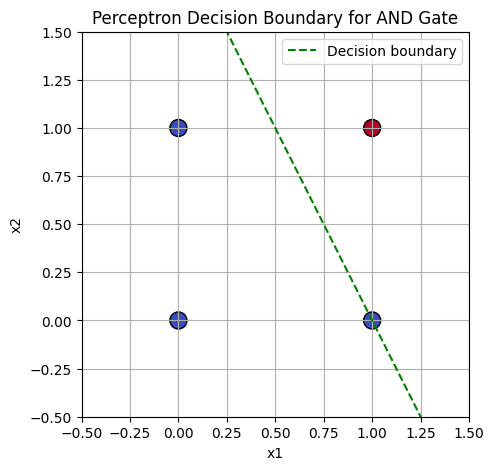

In [7]:
x_line = np.linspace(-0.5, 1.5, 100)
w1, w2 = and_perceptron.weights
b = and_perceptron.bias
y_line = -(w1 * x_line + b) / w2

plt.figure(figsize=(5, 5))
plt.scatter(and_inputs[:, 0], and_inputs[:, 1], c=and_targets, cmap="coolwarm", s=150, edgecolors="black")
plt.plot(x_line, y_line, "g--", label="Decision boundary")
plt.xlim(-0.5, 1.5)
plt.ylim(-0.5, 1.5)
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Perceptron Decision Boundary for AND Gate")
plt.legend()
plt.grid(True)
plt.show()

## Activation Functions

A neuron computes a weighted sum, and an **activation function** then transforms it. Without activation functions a network of many layers would collapse into one linear function, so it could not learn curved or nonlinear patterns.

| Function | Formula | Output range |
|---|---|---|
| Sigmoid | $\sigma(z) = \dfrac{1}{1 + e^{-z}}$ | (0, 1) |
| ReLU | $\max(0, z)$ | [0, infinity) |
| Tanh | $\tanh(z) = \dfrac{e^{z} - e^{-z}}{e^{z} + e^{-z}}$ | (-1, 1) |

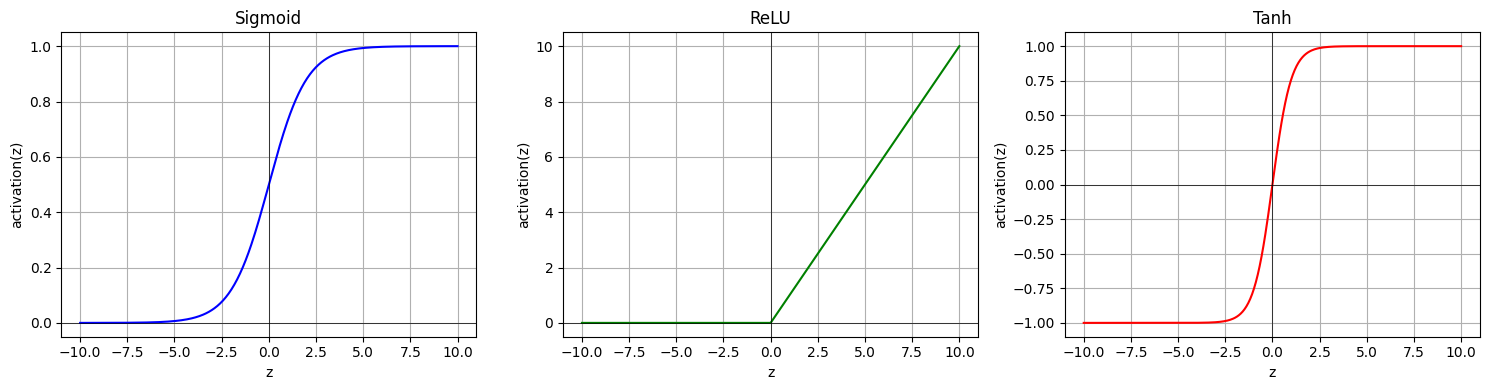

In [8]:
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))


def relu(z):
    return np.maximum(0, z)


def tanh(z):
    return np.tanh(z)


z_values = np.linspace(-10, 10, 400)

figure, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(z_values, sigmoid(z_values), color="blue")
axes[0].set_title("Sigmoid")

axes[1].plot(z_values, relu(z_values), color="green")
axes[1].set_title("ReLU")

axes[2].plot(z_values, tanh(z_values), color="red")
axes[2].set_title("Tanh")

for axis in axes:
    axis.set_xlabel("z")
    axis.set_ylabel("activation(z)")
    axis.grid(True)
    axis.axhline(0, color="black", linewidth=0.5)
    axis.axvline(0, color="black", linewidth=0.5)

plt.tight_layout()
plt.show()

## Forward Propagation

**Forward propagation** is the process in which input features travel through the network, layer by layer, to produce a prediction.

For a network with one hidden layer:

1. Hidden layer weighted sum: $Z_1 = X W_1 + b_1$
2. Hidden layer activation: $A_1 = \tanh(Z_1)$
3. Output layer weighted sum: $Z_2 = A_1 W_2 + b_2$
4. Output layer activation: $A_2 = \sigma(Z_2)$

$A_2$ is the predicted probability that the sample belongs to class 1.

### Dataset used from here onwards
We use the **make_moons** dataset: two interleaving half circles. It is a **nonlinear** problem, so a straight line (like a single perceptron) cannot separate the two classes.

Training features shape: (300, 2)
Training labels shape: (300, 1)
Testing features shape: (100, 2)
Testing labels shape: (100, 1)


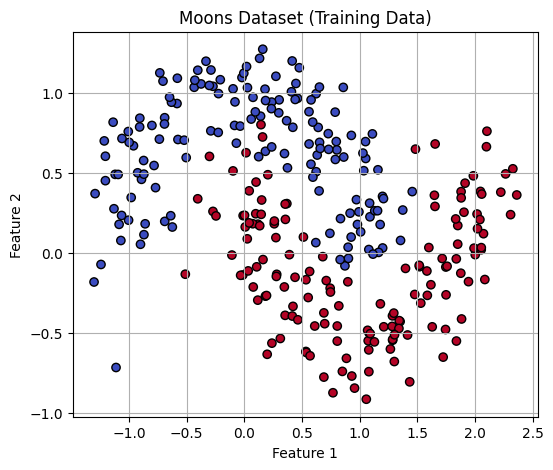

In [9]:
X_moons, y_moons = make_moons(n_samples=400, noise=0.2, random_state=42)

X_train_nn, X_test_nn, y_train_nn, y_test_nn = train_test_split(
    X_moons, y_moons, test_size=0.25, random_state=42, stratify=y_moons
)

y_train_nn = y_train_nn.reshape(-1, 1)
y_test_nn = y_test_nn.reshape(-1, 1)

print("Training features shape:", X_train_nn.shape)
print("Training labels shape:", y_train_nn.shape)
print("Testing features shape:", X_test_nn.shape)
print("Testing labels shape:", y_test_nn.shape)

plt.figure(figsize=(6, 5))
plt.scatter(X_train_nn[:, 0], X_train_nn[:, 1], c=y_train_nn.ravel(), cmap="coolwarm", edgecolors="black")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Moons Dataset (Training Data)")
plt.grid(True)
plt.show()

In [10]:
def initialize_parameters(input_size, hidden_size, output_size, seed=42):
    rng = np.random.default_rng(seed)
    parameters = {
        "W1": rng.normal(0, 1, (input_size, hidden_size)) * np.sqrt(1 / input_size),
        "b1": np.zeros((1, hidden_size)),
        "W2": rng.normal(0, 1, (hidden_size, output_size)) * np.sqrt(1 / hidden_size),
        "b2": np.zeros((1, output_size)),
    }
    return parameters


def forward_propagation(X, parameters):
    Z1 = np.dot(X, parameters["W1"]) + parameters["b1"]
    A1 = tanh(Z1)
    Z2 = np.dot(A1, parameters["W2"]) + parameters["b2"]
    A2 = sigmoid(Z2)
    cache = {"Z1": Z1, "A1": A1, "Z2": Z2, "A2": A2}
    return A2, cache

In [11]:
demo_parameters = initialize_parameters(input_size=2, hidden_size=4, output_size=1, seed=42)
sample_inputs = X_train_nn[:5]

sample_probabilities, sample_cache = forward_propagation(sample_inputs, demo_parameters)

print("Input shape:", sample_inputs.shape)
print("Hidden layer output shape (A1):", sample_cache["A1"].shape)
print("Output shape (A2):", sample_probabilities.shape)
print()
print("Predicted probabilities (untrained network):")
print(np.round(sample_probabilities, 4))
print()
print("Actual labels:")
print(y_train_nn[:5].ravel())

Input shape: (5, 2)
Hidden layer output shape (A1): (5, 4)
Output shape (A2): (5, 1)

Predicted probabilities (untrained network):
[[0.4928]
 [0.5525]
 [0.384 ]
 [0.673 ]
 [0.4593]]

Actual labels:
[1 0 0 1 0]


## Loss Functions

A **loss function** measures how far the predicted probabilities are from the actual labels. Training tries to make the loss as small as possible.

For binary classification we use **Binary Cross-Entropy (BCE)**:

$$L = -\frac{1}{m}\sum_{i=1}^{m}\Big[\,y_i \log(\hat{y}_i) + (1 - y_i)\log(1 - \hat{y}_i)\Big]$$

- If the true label is 1, the loss is $-\log(\hat{y})$: it is small when $\hat{y}$ is close to 1 and very large when $\hat{y}$ is close to 0.
- If the true label is 0, the loss is $-\log(1-\hat{y})$: it is small when $\hat{y}$ is close to 0.

Predictions are clipped to a tiny range so that $\log(0)$ never occurs.

In [12]:
def binary_cross_entropy(y_true, y_pred):
    epsilon = 1e-12
    y_pred = np.clip(y_pred, epsilon, 1 - epsilon)
    return -np.mean(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))


actual_labels = np.array([1, 0, 1, 0])
good_predictions = np.array([0.95, 0.05, 0.90, 0.10])
uncertain_predictions = np.array([0.50, 0.50, 0.50, 0.50])
bad_predictions = np.array([0.05, 0.95, 0.10, 0.90])

print("Actual labels:", actual_labels)
print()
print("Good predictions     :", good_predictions, "-> loss =", round(binary_cross_entropy(actual_labels, good_predictions), 4))
print("Uncertain predictions:", uncertain_predictions, "-> loss =", round(binary_cross_entropy(actual_labels, uncertain_predictions), 4))
print("Bad predictions      :", bad_predictions, "-> loss =", round(binary_cross_entropy(actual_labels, bad_predictions), 4))

Actual labels: [1 0 1 0]

Good predictions     : [0.95 0.05 0.9  0.1 ] -> loss = 0.0783
Uncertain predictions: [0.5 0.5 0.5 0.5] -> loss = 0.6931
Bad predictions      : [0.05 0.95 0.1  0.9 ] -> loss = 2.6492


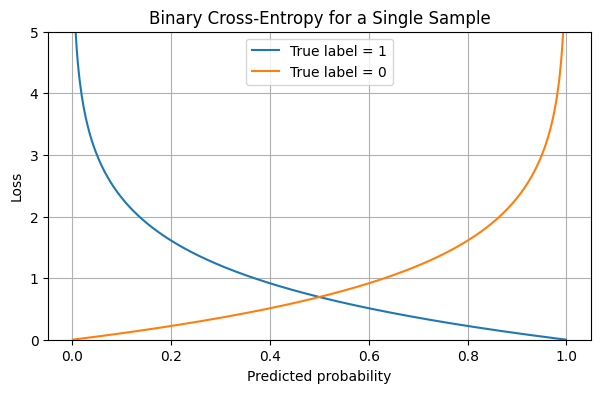

Loss of the untrained demo network on training data: 0.654


In [13]:
probabilities = np.linspace(0.001, 0.999, 500)
loss_when_label_is_one = -np.log(probabilities)
loss_when_label_is_zero = -np.log(1 - probabilities)

plt.figure(figsize=(7, 4))
plt.plot(probabilities, loss_when_label_is_one, label="True label = 1")
plt.plot(probabilities, loss_when_label_is_zero, label="True label = 0")
plt.xlabel("Predicted probability")
plt.ylabel("Loss")
plt.title("Binary Cross-Entropy for a Single Sample")
plt.ylim(0, 5)
plt.legend()
plt.grid(True)
plt.show()

demo_loss = binary_cross_entropy(y_train_nn, forward_propagation(X_train_nn, demo_parameters)[0])
print("Loss of the untrained demo network on training data:", round(demo_loss, 4))

## Backward Propagation

**Backpropagation** calculates how much each weight and bias contributed to the loss, using the **chain rule** of calculus. These gradients tell us in which direction to change every parameter to reduce the loss.

The chain rule says: if $L$ depends on $A_2$, which depends on $Z_2$, which depends on $W_2$, then

$$\frac{\partial L}{\partial W_2} = \frac{\partial L}{\partial A_2}\cdot\frac{\partial A_2}{\partial Z_2}\cdot\frac{\partial Z_2}{\partial W_2}$$

For sigmoid output with binary cross-entropy loss, the first two factors combine into a very simple result, $\dfrac{\partial L}{\partial Z_2} = A_2 - y$.

**Gradients for our network** (m = number of samples):

| Step | Formula |
|---|---|
| Output error | $dZ_2 = A_2 - y$ |
| Output weights | $dW_2 = \frac{1}{m} A_1^{T} dZ_2$ |
| Output bias | $db_2 = \frac{1}{m}\sum dZ_2$ |
| Hidden activation error | $dA_1 = dZ_2 W_2^{T}$ |
| Hidden error | $dZ_1 = dA_1 \odot (1 - A_1^{2})$ since the derivative of tanh is $1 - \tanh^2$ |
| Hidden weights | $dW_1 = \frac{1}{m} X^{T} dZ_1$ |
| Hidden bias | $db_1 = \frac{1}{m}\sum dZ_1$ |

In [14]:
def backward_propagation(X, y, parameters, cache):
    sample_count = X.shape[0]
    A1 = cache["A1"]
    A2 = cache["A2"]

    dZ2 = A2 - y
    dW2 = np.dot(A1.T, dZ2) / sample_count
    db2 = np.sum(dZ2, axis=0, keepdims=True) / sample_count

    dA1 = np.dot(dZ2, parameters["W2"].T)
    dZ1 = dA1 * (1 - A1 ** 2)
    dW1 = np.dot(X.T, dZ1) / sample_count
    db1 = np.sum(dZ1, axis=0, keepdims=True) / sample_count

    gradients = {"dW1": dW1, "db1": db1, "dW2": dW2, "db2": db2}
    return gradients

In [15]:
def loss_for_parameters(X, y, parameters):
    predictions, _ = forward_propagation(X, parameters)
    return binary_cross_entropy(y, predictions)


def numerical_gradient(X, y, parameters, key, row, column, epsilon=1e-5):
    original_value = parameters[key][row, column]

    parameters[key][row, column] = original_value + epsilon
    loss_plus = loss_for_parameters(X, y, parameters)

    parameters[key][row, column] = original_value - epsilon
    loss_minus = loss_for_parameters(X, y, parameters)

    parameters[key][row, column] = original_value
    return (loss_plus - loss_minus) / (2 * epsilon)


check_parameters = initialize_parameters(2, 4, 1, seed=42)
check_predictions, check_cache = forward_propagation(X_train_nn, check_parameters)
analytical_gradients = backward_propagation(X_train_nn, y_train_nn, check_parameters, check_cache)

checks = [("W1", 0, 0, "dW1"), ("W1", 1, 2, "dW1"), ("W2", 3, 0, "dW2"), ("b1", 0, 1, "db1"), ("b2", 0, 0, "db2")]

print("Parameter      Analytical     Numerical      Difference")
for key, row, column, gradient_key in checks:
    analytical = analytical_gradients[gradient_key][row, column]
    numerical = numerical_gradient(X_train_nn, y_train_nn, check_parameters, key, row, column)
    print(f"{key}[{row},{column}]".ljust(14), f"{analytical:12.8f}", f"{numerical:14.8f}", f"{abs(analytical - numerical):14.2e}")

Parameter      Analytical     Numerical      Difference
W1[0,0]          0.00028729     0.00028729       3.50e-12
W1[1,2]          0.07565671     0.07565671       4.71e-14
W2[3,0]         -0.07124805    -0.07124805       4.03e-12
b1[0,1]         -0.00297206    -0.00297206       6.57e-12
b2[0,0]          0.09128216     0.09128216       1.86e-12


## Optimizers

An **optimizer** uses the gradients to update the parameters so that the loss decreases.

### Stochastic Gradient Descent (SGD)
$$\theta \leftarrow \theta - \eta \, \nabla_\theta L$$
Each parameter moves a step of size $\eta$ (learning rate) against its gradient. It is simple, but uses the same learning rate for every parameter and can be slow.

### Adam (Adaptive Moment Estimation)
Adam keeps running averages of the gradient (first moment $m$) and of the squared gradient (second moment $v$):

$$m \leftarrow \beta_1 m + (1-\beta_1) g \qquad v \leftarrow \beta_2 v + (1-\beta_2) g^2$$
$$\hat{m} = \frac{m}{1-\beta_1^{t}} \qquad \hat{v} = \frac{v}{1-\beta_2^{t}} \qquad \theta \leftarrow \theta - \eta\,\frac{\hat{m}}{\sqrt{\hat{v}} + \varepsilon}$$

It combines momentum with a separate adaptive step size for each parameter, so it usually converges faster.


In [16]:
class SGD:
    def __init__(self, learning_rate=0.1):
        self.learning_rate = learning_rate

    def update(self, parameters, gradients):
        for key in parameters:
            parameters[key] = parameters[key] - self.learning_rate * gradients["d" + key]


class Adam:
    def __init__(self, learning_rate=0.01, beta1=0.9, beta2=0.999, epsilon=1e-8):
        self.learning_rate = learning_rate
        self.beta1 = beta1
        self.beta2 = beta2
        self.epsilon = epsilon
        self.first_moment = {}
        self.second_moment = {}
        self.step_count = 0

    def update(self, parameters, gradients):
        if not self.first_moment:
            for key in parameters:
                self.first_moment[key] = np.zeros_like(parameters[key])
                self.second_moment[key] = np.zeros_like(parameters[key])

        self.step_count += 1
        for key in parameters:
            gradient = gradients["d" + key]
            self.first_moment[key] = self.beta1 * self.first_moment[key] + (1 - self.beta1) * gradient
            self.second_moment[key] = self.beta2 * self.second_moment[key] + (1 - self.beta2) * gradient ** 2
            corrected_first = self.first_moment[key] / (1 - self.beta1 ** self.step_count)
            corrected_second = self.second_moment[key] / (1 - self.beta2 ** self.step_count)
            parameters[key] = parameters[key] - self.learning_rate * corrected_first / (np.sqrt(corrected_second) + self.epsilon)

In [17]:
sgd_demo_parameters = {"w": np.array([2.0])}
adam_demo_parameters = {"w": np.array([2.0])}
demo_gradients = {"dw": np.array([0.5])}

sgd_demo = SGD(learning_rate=0.1)
adam_demo = Adam(learning_rate=0.1)

print("Step | SGD w      | Adam w")
print("  0  |", round(float(sgd_demo_parameters["w"][0]), 5), "   |", round(float(adam_demo_parameters["w"][0]), 5))
for step in range(1, 5):
    sgd_demo.update(sgd_demo_parameters, demo_gradients)
    adam_demo.update(adam_demo_parameters, demo_gradients)
    print(" ", step, " |", round(float(sgd_demo_parameters["w"][0]), 5), "  |", round(float(adam_demo_parameters["w"][0]), 5))

Step | SGD w      | Adam w
  0  | 2.0    | 2.0
  1  | 1.95   | 1.9
  2  | 1.9   | 1.8
  3  | 1.85   | 1.7
  4  | 1.8   | 1.6


SGD  final training loss: 0.3414
Adam final training loss: 0.0707


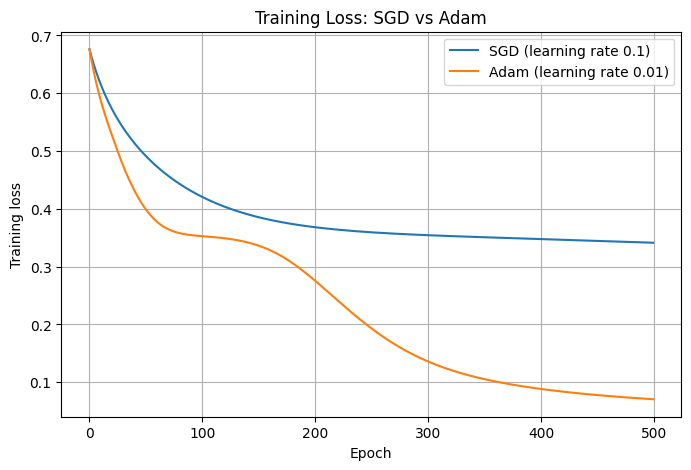

In [18]:
def train_with_optimizer(optimizer, X, y, epochs=500, hidden_size=8, seed=42):
    parameters = initialize_parameters(X.shape[1], hidden_size, 1, seed=seed)
    loss_history = []
    for epoch in range(epochs):
        predictions, cache = forward_propagation(X, parameters)
        loss_history.append(binary_cross_entropy(y, predictions))
        gradients = backward_propagation(X, y, parameters, cache)
        optimizer.update(parameters, gradients)
    return parameters, loss_history


sgd_parameters, sgd_losses = train_with_optimizer(SGD(learning_rate=0.1), X_train_nn, y_train_nn)
adam_parameters, adam_losses = train_with_optimizer(Adam(learning_rate=0.01), X_train_nn, y_train_nn)

print("SGD  final training loss:", round(sgd_losses[-1], 4))
print("Adam final training loss:", round(adam_losses[-1], 4))

plt.figure(figsize=(8, 5))
plt.plot(sgd_losses, label="SGD (learning rate 0.1)")
plt.plot(adam_losses, label="Adam (learning rate 0.01)")
plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("Training Loss: SGD vs Adam")
plt.legend()
plt.grid(True)
plt.show()

In [19]:
class NeuralNetwork:
    def __init__(self, input_size, hidden_size, output_size, learning_rate=0.01, seed=42):
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.output_size = output_size
        self.optimizer = Adam(learning_rate=learning_rate)
        self.parameters = self.initialize_parameters(seed)
        self.loss_history = []

    def initialize_parameters(self, seed):
        rng = np.random.default_rng(seed)
        parameters = {
            "W1": rng.normal(0, 1, (self.input_size, self.hidden_size)) * np.sqrt(1 / self.input_size),
            "b1": np.zeros((1, self.hidden_size)),
            "W2": rng.normal(0, 1, (self.hidden_size, self.output_size)) * np.sqrt(1 / self.hidden_size),
            "b2": np.zeros((1, self.output_size)),
        }
        return parameters

    def forward(self, X):
        Z1 = np.dot(X, self.parameters["W1"]) + self.parameters["b1"]
        A1 = tanh(Z1)
        Z2 = np.dot(A1, self.parameters["W2"]) + self.parameters["b2"]
        A2 = sigmoid(Z2)
        cache = {"A1": A1, "A2": A2}
        return A2, cache

    def compute_loss(self, y_true, y_pred):
        return binary_cross_entropy(y_true, y_pred)

    def backward(self, X, y, cache):
        sample_count = X.shape[0]
        dZ2 = cache["A2"] - y
        dW2 = np.dot(cache["A1"].T, dZ2) / sample_count
        db2 = np.sum(dZ2, axis=0, keepdims=True) / sample_count
        dA1 = np.dot(dZ2, self.parameters["W2"].T)
        dZ1 = dA1 * (1 - cache["A1"] ** 2)
        dW1 = np.dot(X.T, dZ1) / sample_count
        db1 = np.sum(dZ1, axis=0, keepdims=True) / sample_count
        return {"dW1": dW1, "db1": db1, "dW2": dW2, "db2": db2}

    def fit(self, X, y, epochs=1000, print_every=200):
        self.loss_history = []
        for epoch in range(1, epochs + 1):
            predictions, cache = self.forward(X)
            loss = self.compute_loss(y, predictions)
            self.loss_history.append(loss)
            gradients = self.backward(X, y, cache)
            self.optimizer.update(self.parameters, gradients)
            if epoch % print_every == 0 or epoch == 1:
                print(f"Epoch {epoch:4d} | Loss: {loss:.4f}")

    def predict_proba(self, X):
        probabilities, _ = self.forward(X)
        return probabilities

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

    def evaluate(self, X, y):
        probabilities = self.predict_proba(X)
        loss = self.compute_loss(y, probabilities)
        accuracy = np.mean(self.predict(X) == y)
        return loss, accuracy

In [20]:
network = NeuralNetwork(input_size=2, hidden_size=8, output_size=1, learning_rate=0.01, seed=42)

initial_loss, initial_accuracy = network.evaluate(X_train_nn, y_train_nn)
print("Before training -> loss:", round(initial_loss, 4), "| accuracy:", round(initial_accuracy, 4))
print()

network.fit(X_train_nn, y_train_nn, epochs=1000, print_every=200)

Before training -> loss: 0.6761 | accuracy: 0.6133

Epoch    1 | Loss: 0.6761
Epoch  200 | Loss: 0.2769
Epoch  400 | Loss: 0.0886
Epoch  600 | Loss: 0.0617
Epoch  800 | Loss: 0.0528
Epoch 1000 | Loss: 0.0480


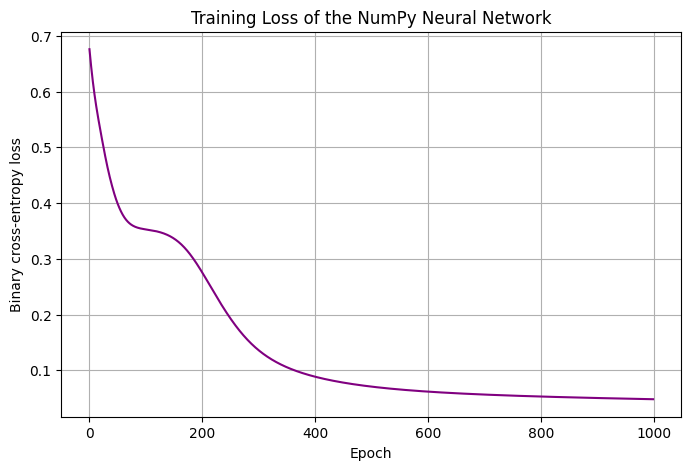

In [21]:
plt.figure(figsize=(8, 5))
plt.plot(network.loss_history, color="purple")
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy loss")
plt.title("Training Loss of the NumPy Neural Network")
plt.grid(True)
plt.show()

In [22]:
train_loss, train_accuracy = network.evaluate(X_train_nn, y_train_nn)
test_loss, test_accuracy = network.evaluate(X_test_nn, y_test_nn)

print("Training loss    :", round(train_loss, 4))
print("Training accuracy:", round(train_accuracy, 4))
print("Test loss        :", round(test_loss, 4))
print("Test accuracy    :", round(test_accuracy, 4))
print()
print("Confusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(y_test_nn.ravel(), network.predict(X_test_nn).ravel()))

Training loss    : 0.048
Training accuracy: 0.98
Test loss        : 0.1875
Test accuracy    : 0.93

Confusion matrix (rows = actual, columns = predicted):
[[46  4]
 [ 3 47]]


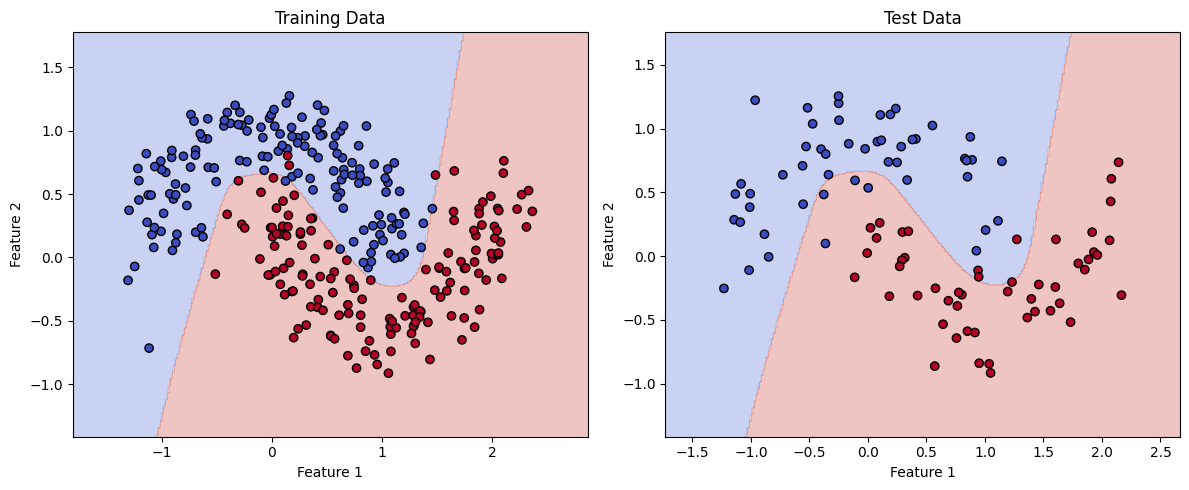

In [23]:
def plot_decision_boundary(model, X, y, title):
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    grid_x, grid_y = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
    grid_points = np.c_[grid_x.ravel(), grid_y.ravel()]
    grid_predictions = model.predict(grid_points).reshape(grid_x.shape)

    plt.contourf(grid_x, grid_y, grid_predictions, alpha=0.3, cmap="coolwarm")
    plt.scatter(X[:, 0], X[:, 1], c=y.ravel(), cmap="coolwarm", edgecolors="black")
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.title(title)


figure = plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plot_decision_boundary(network, X_train_nn, y_train_nn, "Training Data")
plt.subplot(1, 2, 2)
plot_decision_boundary(network, X_test_nn, y_test_nn, "Test Data")
plt.tight_layout()
plt.show()

In [24]:
np.savez(
    "neural_network_parameters.npz",
    W1=network.parameters["W1"],
    b1=network.parameters["b1"],
    W2=network.parameters["W2"],
    b2=network.parameters["b2"],
)
print("Saved file size (bytes):", os.path.getsize("neural_network_parameters.npz"))

loaded_file = np.load("neural_network_parameters.npz")
print("Arrays stored in the file:", loaded_file.files)

restored_network = NeuralNetwork(input_size=2, hidden_size=8, output_size=1, seed=0)
restored_network.parameters = {
    "W1": loaded_file["W1"],
    "b1": loaded_file["b1"],
    "W2": loaded_file["W2"],
    "b2": loaded_file["b2"],
}

original_test_predictions = network.predict(X_test_nn)
restored_test_predictions = restored_network.predict(X_test_nn)

print()
print("Class predictions identical:", np.array_equal(original_test_predictions, restored_test_predictions))
print("Probabilities identical    :", np.allclose(network.predict_proba(X_test_nn), restored_network.predict_proba(X_test_nn)))
print("Restored network test accuracy:", round(restored_network.evaluate(X_test_nn, y_test_nn)[1], 4))

Saved file size (bytes): 1230
Arrays stored in the file: ['W1', 'b1', 'W2', 'b2']

Class predictions identical: True
Probabilities identical    : True
Restored network test accuracy: 0.93
